In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
def compute_cumulative_outcome_fractions(df, masses, N):
    """
    df      : DataFrame with columns ['mass', 'time', 'particle_id', 'result']
              where result is 'Ejected' or 'Captured', and each row represents
              the time at which that particle's outcome occurred
    masses  : list/array of unique mass values, in the same order as N
    N       : list/array of total particle counts, one per mass in `masses`

    Returns
    -------
    ejection_df, capture_df : DataFrames indexed by mass, columns = sorted
                               unique time values, entries = CUMULATIVE
                               fraction of N with that result by that time
                               (i.e. fraction ejected/captured at or before
                               each time, monotonically non-decreasing
                               across each row)
    """
    if len(masses) != len(N):
        raise ValueError("masses and N must be the same length")

    mass_to_N = dict(zip(masses, N))

    times = np.sort(df["time"].unique())

    ejection_df = pd.DataFrame(index=masses, columns=times, dtype=float)
    capture_df = pd.DataFrame(index=masses, columns=times, dtype=float)

    for mass in masses:
        mass_df = df[df["mass"] == mass]
        denom = mass_to_N[mass]

        counts = (
            mass_df.groupby(["time", "result"])
            .size()
            .unstack(fill_value=0)
        )

        # reindex to the full sorted time axis, filling any missing times
        # with 0 new outcomes at that time, then cumsum across time
        ejected_counts = counts.get("Ejected", pd.Series(0, index=counts.index))
        captured_counts = counts.get("Captured", pd.Series(0, index=counts.index))

        ejected_counts = ejected_counts.reindex(times, fill_value=0)
        captured_counts = captured_counts.reindex(times, fill_value=0)

        ejection_df.loc[mass] = (ejected_counts.cumsum() / denom).values
        capture_df.loc[mass] = (captured_counts.cumsum() / denom).values

    return ejection_df, capture_df

In [26]:
df=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2282626_ejection_results.txt', header=None)

In [27]:
df.columns=['mass','time','result','particle_id']

In [28]:
df.mass.unique()

array([0.01      , 0.00501187, 0.00251189])

In [39]:
df.tail()

,mass,time,result,particle_id
1205,0.002512,8.778981e+05,Ejected,129
1206,0.002512,9.937527e+05,Captured,491
1207,0.010000,1.836839e+06,Ejected,438
1208,0.005012,3.777546e+06,Ejected,471
1209,0.002512,1.085637e+06,Captured,275


In [30]:
ejection_df,c=compute_cumulative_outcome_fractions(df, df.mass.unique(), [800,800,800])

In [31]:
ejection_df

,0.000000e+00,6.982524e+03,1.492556e+04,1.592060e+04,1.691563e+04,1.791067e+04,1.890571e+04,1.990074e+04,2.089578e+04,2.189082e+04,...,9.937527e+05,1.005483e+06,1.013463e+06,1.070660e+06,1.085637e+06,1.232851e+06,1.836839e+06,1.859346e+06,3.153108e+06,3.777546e+06
0.010000,0.0,0.0,0.0,0.00375,0.0075,0.01,0.01625,0.0275,0.0375,0.05,...,0.60125,0.60125,0.60125,0.60250,0.60250,0.60375,0.60500,0.60500,0.60500,0.60500
0.005012,0.0,0.0,0.0,0.00000,0.0000,0.00,0.00000,0.0000,0.0000,0.00,...,0.49500,0.49625,0.49750,0.49750,0.49750,0.49750,0.49750,0.49875,0.50000,0.50125
0.002512,0.0,0.0,0.0,0.00000,0.0000,0.00,0.00000,0.0000,0.0000,0.00,...,0.36375,0.36375,0.36375,0.36375,0.36375,0.36375,0.36375,0.36375,0.36375,0.36375


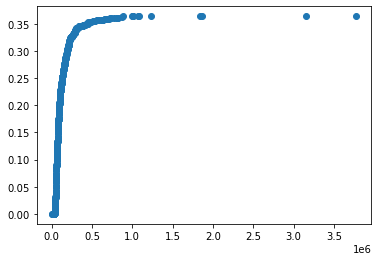

In [37]:
plt.scatter(ejection_df.columns,ejection_df.loc[ejection_df.index.unique()[2]])

In [24]:


def find_t_stop(ejection_df, index):
    f = ejection_df.iloc[index].to_numpy()
    t = ejection_df.columns.to_numpy(dtype=float)

    peak_slope = -np.inf
    t_peak = None
    consecutive = 0

    for i in range(5, len(t)):
        # Update peak slope using a 5-point window
        slope = (f[i] - f[i-5]) / (t[i] - t[i-5])

        if slope > peak_slope:
            peak_slope = slope
            t_peak = t[i]

        # Look back 3*t_peak
        t_back = t[i] - 3*t_peak

        if f[i] < 0.07 or t_back < t[0]:
            continue

        j = np.searchsorted(t, t_back, side='right') - 1

        if f[i] - f[j] < 0.04:
            consecutive += 1
        else:
            consecutive = 0

        if consecutive >= 3:
            return t[i]

    return None



In [25]:
t_stop = find_t_stop(ejection_df, index=1)
print(t_stop)

260699.7438350171
